# Start


In [41]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 
import pickle

# Load Data

In [42]:
train = pd.read_csv('input/train.csv')
test = pd.read_csv('input/test.csv')
print("Train Shape:", train.shape)
print("Test Shape:", test.shape)
print(train.info())

Train Shape: (1460, 81)
Test Shape: (1459, 80)
<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1

# Chec for NULL values 

# Train Data

In [43]:
print(train.isnull().sum())

Id                 0
MSSubClass         0
MSZoning           0
LotFrontage      259
LotArea            0
                ... 
MoSold             0
YrSold             0
SaleType           0
SaleCondition      0
SalePrice          0
Length: 81, dtype: int64


# Test Data

In [44]:
print(test.isnull().sum())

Id                 0
MSSubClass         0
MSZoning           4
LotFrontage      227
LotArea            0
                ... 
MiscVal            0
MoSold             0
YrSold             0
SaleType           1
SaleCondition      0
Length: 80, dtype: int64


# For Train Data

In [45]:
cat_col_train = ['FireplaceQu','GarageType','GarageFinish','MasVnrType','BsmtQual',
                  'BsmtCond','BsmtExposure','BsmtFinType1','BsmtFinType2','FireplaceQu',
                  'GarageQual','GarageCond']

ncat_col_train = ['LotFrontage','GarageYrBlt','MasVnrArea']

for i in cat_col_train:
    train[i] = train[i].fillna(train[i].mode()[0])

for j in ncat_col_train:
    train[j] = train[j].fillna(train[j].mean())

# For Test Data

In [46]:
cat_col_test = ['FireplaceQu','GarageType','GarageFinish','MasVnrType','BsmtQual',
                 'BsmtCond','BsmtExposure','BsmtFinType1','BsmtFinType2','FireplaceQu',
                 'GarageQual','GarageCond','MSZoning','Utilities','Exterior1st','Exterior2nd',
                 'KitchenQual','Functional','SaleType']

ncat_col_test = ['LotFrontage','GarageYrBlt','MasVnrArea','BsmtFinSF1','BsmtFinSF2',
                  'BsmtUnfSF','TotalBsmtSF','BsmtFullBath','BsmtHalfBath','GarageCars','GarageArea']

for i in cat_col_test:
    test[i] = test[i].fillna(test[i].mode()[0])

for j in ncat_col_test:
    test[j] = test[j].fillna(test[j].mean())


# Drop Colmns

Train Shape:  (1460, 76)
Test Shape:  (1459, 75)


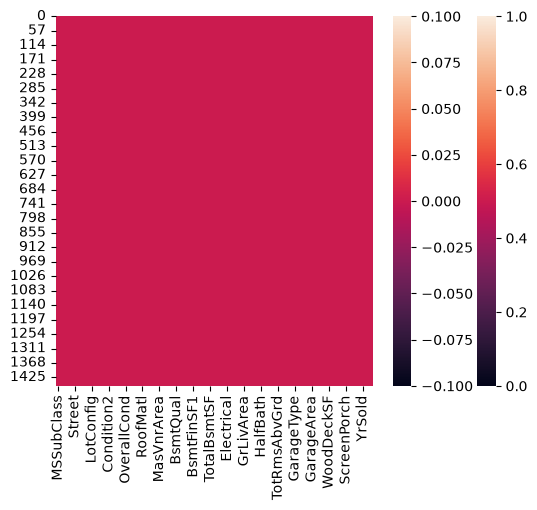

In [47]:
to_drop = ['Id','Alley','PoolQC','Fence','MiscFeature']

for k in to_drop:
    train.drop([k], axis = 1, inplace = True)
    test.drop([k], axis = 1, inplace = True)

sns.heatmap(train.isnull())
sns.heatmap(test.isnull())

print("Train Shape: ", train.shape)
print("Test Shape: ", test.shape)



In [48]:
final_df = pd.concat([train,test], axis = 0)
final_df.shape

(2919, 76)

# One-hot endcoding

In [49]:
final_df = pd.concat([train,test], axis = 0)
final_df.shape
# (2919, 76)

all_cat_col = ['MSZoning','Street','LotShape','LandContour','Utilities','LotConfig','LandSlope',
    'Neighborhood','Condition1','Condition2','BldgType','HouseStyle','RoofStyle','RoofMatl',
    'Exterior1st','Exterior2nd','MasVnrType','ExterQual','ExterCond','Foundation','BsmtQual',
    'BsmtCond','BsmtExposure','BsmtFinType1','BsmtFinType2','Heating','HeatingQC','CentralAir',
    'Electrical','KitchenQual','Functional','FireplaceQu','GarageType','GarageFinish','GarageQual',
    'GarageCond','PavedDrive','SaleType','SaleCondition']

def cat_onehot_encoding(multicol):
    df_final = final_df
    i = 0
    for fields in multicol:
        print(fields)
        df1 = pd.get_dummies(final_df[fields], drop_first = True)

        final_df.drop([fields], axis = 1, inplace = True)
        if i == 0:
            df_final = df1.copy()
        else:
            df_final = pd.concat([df_final, df1], axis = 1)
        i = i + 1

    df_final = pd.concat([final_df, df_final], axis = 1)

    return df_final

final_df = cat_onehot_encoding(all_cat_col)

final_df.shape

MSZoning
Street
LotShape
LandContour
Utilities
LotConfig
LandSlope
Neighborhood
Condition1
Condition2
BldgType
HouseStyle
RoofStyle
RoofMatl
Exterior1st
Exterior2nd
MasVnrType
ExterQual
ExterCond
Foundation
BsmtQual
BsmtCond
BsmtExposure
BsmtFinType1
BsmtFinType2
Heating
HeatingQC
CentralAir
Electrical
KitchenQual
Functional
FireplaceQu
GarageType
GarageFinish
GarageQual
GarageCond
PavedDrive
SaleType
SaleCondition


(2919, 236)

# Remove duplicate columns

In [50]:
final_df = final_df.loc[:, ~final_df.columns.duplicated()]
final_df.shape

(2919, 176)

# Divide data for train and test

In [51]:
df_train = final_df.iloc[:1460,:]
df_test = final_df.iloc[1460:,:]

In [52]:
df_test.drop(['SalePrice'], axis = 1, inplace = True)

In [53]:
print("Train Shape: ", df_train.shape)
print("Test Shape: ", df_test.shape)

Train Shape:  (1460, 176)
Test Shape:  (1459, 175)


# Traning Data

In [54]:
x_train = df_train.drop(['SalePrice'], axis = 1)
y_train = df_train['SalePrice']

# XGBoost

In [89]:
import xgboost

xgb_model = xgboost.XGBRegressor()
xgb_model.fit(x_train, y_train)

param = {
    'n_estimators': [100, 500, 900, 1100, 1500],
    'max_depth': [2,3,5,10,15],
    'learning_rate': [0.05, 0.1, 0.15, 0.2],
    'min_child_weight': [1,2,3,4],
    'booster': ['gbtree','gblinear'],
    'base_score': [0.25, 0.5, 0.75, 1]
}

from sklearn.model_selection import RandomizedSearchCV

random_cv = RandomizedSearchCV(estimator=xgb_model,
                                param_distributions = param,
                                cv=5, n_iter=50,
                                scoring = 'neg_mean_absolute_error', n_jobs = 4,
                                verbose = 5,
                                return_train_score = True,
                                random_state = 42)
random_cv.fit(x_train, y_train)

random_cv.best_estimator_

xgb_model = xgboost.XGBRegressor(base_score=0.25, booster='gbtree', colsample_bylevel=1,
        colsample_bynode=1, colsample_bytree=1, gamma=0, gpu_id=-1,
        importance_type='gain', interaction_constraints='',
        learning_rate=0.1, max_delta_step=0, max_depth=2,
        min_child_weight=1, monotone_constraints='()',
        n_estimators=900, n_jobs=0, num_parallel_tree=1,
        objective='reg:squarederror', random_state=0, reg_alpha=0,
        reg_lambda=1, scale_pos_weight=1, subsample=1, tree_method='exact',
        validate_parameters=1, verbosity=None)

xgb_model = xgboost.XGBRegressor(
    base_score=0.25,
    booster='gbtree',
    learning_rate=0.1,
    max_depth=4,
    min_child_weight=1,
    n_estimators=500,
    objective='reg:squarederror',
    tree_method='hist',
    device='cpu',
    random_state=0
)

xgb_model.fit(x_train, y_train)

Fitting 5 folds for each of 50 candidates, totalling 250 fits


,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",0.25
,booster,'gbtree'
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",'cpu'
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


# Save Model

In [56]:
f = "xgb_model.pkl"
pickle.dump(xgb_model, open(f,'wb'))


# Predictions & sumbmission

In [90]:
import os

pred_xgb = xgb_model.predict(df_test)
print(pred_xgb.shape)

filename_xgb = 'ketqua/sample_sub_xgb3.csv' 
if not os.path.exists(filename_xgb):
    print(f'Chua co file {filename_xgb}, se tao moi.')
    open(filename_xgb, 'w').close()
else:
    print(f'File {filename_xgb} da ton tai, se ghi de.')

sub_df = pd.read_csv('input/sample_submission.csv')
sub_df['SalePrice'] = pred_xgb
sub_df.to_csv(filename_xgb, index=False)
print(f'Da luu ket qua vao {filename_xgb}')

(1459,)
Chua co file ketqua/sample_sub_xgb3.csv, se tao moi.
Da luu ket qua vao ketqua/sample_sub_xgb3.csv


# Decision Tree

In [79]:
from sklearn.tree import DecisionTreeRegressor

dt_model = DecisionTreeRegressor(
    random_state=42,
    max_depth=7,             
    min_samples_split=10,
    min_samples_leaf=5,
    max_features='sqrt'
)
dt_model.fit(x_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",7
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",'sqrt'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with

# Predictions

In [80]:
pred_dt = dt_model.predict(df_test)
print(pred_dt.shape)

(1459,)


# Submissions

In [ ]:
sub_df = pd.read_csv('input/sample_submission.csv')
sub_df['SalePrice'] = pred_dt
sub_df.to_csv('ketqua/sample_sub_dt_maxdepth7.csv', index=False)

# Artificial Neural Network

In [62]:
import keras
from keras import ops
from keras.models import Sequential
from keras.layers import Dense

def root_mean_squared_error(y_true, y_pred):
    return ops.sqrt(ops.mean(ops.square(y_pred - y_true)))

# Model

In [76]:
from keras import Input
from keras.callbacks import EarlyStopping

early_stop = EarlyStopping(monitor='val_loss', patience=30, restore_best_weights=True)

x_train_nn = x_train.apply(pd.to_numeric, errors='coerce').fillna(0).astype('float32')
y_train_nn = pd.to_numeric(y_train, errors='coerce').astype('float32')

nn_model = Sequential([
    Input(shape=(x_train_nn.shape[1],)),
    Dense(50, kernel_initializer='he_uniform', activation='relu'),
    Dense(25, kernel_initializer='he_uniform', activation='relu'),
    Dense(50, kernel_initializer='he_uniform', activation='relu'),
    Dense(1, kernel_initializer='he_uniform')
])

nn_model.compile(loss=root_mean_squared_error, optimizer='adam')
nn_model.fit(x_train_nn, y_train_nn, validation_split=0.25, batch_size=10, epochs=1000,callbacks=[early_stop])
nn_model.save('nn_model.keras')

Epoch 1/1000
110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 155686.3125 - val_loss: 64253.1719
Epoch 2/1000
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 67054.2812 - val_loss: 58352.0391
Epoch 3/1000
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 59416.5586 - val_loss: 54230.5312
Epoch 4/1000
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 52855.4922 - val_loss: 50400.4258
Epoch 5/1000
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 46069.4180 - val_loss: 45940.9805
Epoch 6/1000
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 40459.3516 - val_loss: 43366.4180
Epoch 7/1000
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 39077.1797 - val_loss: 42420.9141
Epoch 8/1000
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 37154.7227 - val_loss: 42214.0352
Epoch 9/1000
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 36865.9648 - val_loss: 45379.9688
Epoch 10/1000
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 37706.8320 - val_loss: 42137.5625
Epoch 11/1000
110/110 ━━━━━━━━━━━━━━━━

# Predictions

In [77]:
x_test_nn = df_test.apply(pd.to_numeric, errors='coerce').fillna(0).astype('float32')
pred_nn = nn_model.predict(x_test_nn, verbose=0).ravel()
print(pred_nn.shape)

(1459,)


# Submission

In [78]:
sub_df = pd.read_csv('input/sample_submission.csv')
sub_df['SalePrice'] = pred_nn
sub_df.to_csv('ketqua/sample_sub_nn_adamoptimizer.csv', index=False)